In [1]:
import pandas as pd
from sklearn.feature_selection import SelectKBest, f_classif
import matplotlib.pyplot as plt
import seaborn as sns

In [10]:
# Step 1: Load the Dataset After Outlier Detection (Output from outlier Detection Step)
outlierD_data_path = '/content/heart_cleaned_no_outliers_encoded.csv'
df_after_outlierD = pd.read_csv(outlierD_data_path)
print("Dataset loaded after Outlier Ditection:")
print(f"Shape: {df_after_outlierD.shape}")
print("\nData Types (first 10):")
print(df_after_outlierD.dtypes.head(10))
display(df_after_outlierD.head())

Dataset loaded after Outlier Ditection:
Shape: (889, 20)

Data Types (first 10):
age                int64
trestbps           int64
chol               int64
thalach            int64
oldpeak          float64
target             int64
fbs_encoded        int64
exang_encoded      int64
slope_encoded      int64
ca_encoded         int64
dtype: object


,age,trestbps,chol,thalach,oldpeak,target,fbs_encoded,exang_encoded,slope_encoded,ca_encoded,thal_encoded,sex_Female,sex_Male,cp_Asymptomatic,cp_Atypical angina,cp_Non-anginal pain,cp_Typical angina,restecg_0,restecg_1,restecg_2
0,52,125,212,168,1.0,0,1,0,2,2,1,0,1,0,0,0,1,0,1,0
1,53,140,203,155,3.1,0,0,1,0,0,1,0,1,0,0,0,1,1,0,0
2,70,145,174,125,2.6,0,1,1,0,0,1,0,1,0,0,0,1,0,1,0
3,61,148,203,161,0.0,0,1,0,2,1,1,0,1,0,0,0,1,0,1,0
4,58,100,248,122,1.0,1,1,0,1,0,0,1,0,0,0,0,1,1,0,0


In [11]:
# 1. Dataset Before Feature Selection (After Outlier Detection)
# Separate features and target from the outlier Detection output dataset
X_OutlierD = df_after_outlierD.drop('target', axis=1)
y_OutlierD = df_after_outlierD['target']

print("\n--- Dataset Before Feature Selection (After OutlierDetection) ---")
print(f"Features shape: {X_OutlierD.shape}")
print(f"Target shape: {y_OutlierD.shape}")
print("\nFeature columns (first 10):")
print(X_OutlierD.columns.tolist()[:10]) # Show first 10 feature names


--- Dataset Before Feature Selection (After OutlierDetection) ---
Features shape: (889, 19)
Target shape: (889,)

Feature columns (first 10):
['age', 'trestbps', 'chol', 'thalach', 'oldpeak', 'fbs_encoded', 'exang_encoded', 'slope_encoded', 'ca_encoded', 'thal_encoded']


In [12]:
# 2. Apply SelectKBest for Feature Selection
# Select top 10 features based on f_classif score
k_best = 10
selector = SelectKBest(score_func=f_classif, k=k_best)
X_selected = selector.fit_transform(X_OutlierD, y_OutlierD)

In [13]:
# Get the names of the selected features
selected_feature_names = X_OutlierD.columns[selector.get_support()].tolist()
feature_scores = selector.scores_
selected_scores = feature_scores[selector.get_support()]
print(f"\n--- Applied SelectKBest (k={k_best}) ---")
print(f"Original number of features: {X_OutlierD.shape[1]}")
print(f"Number of selected features: {X_selected.shape[1]}")
print("\nSelected Features and their Scores:")
for feat, score in zip(selected_feature_names, selected_scores):
    print(f"  {feat}: {score:.4f}")



--- Applied SelectKBest (k=10) ---
Original number of features: 19
Number of selected features: 10

Selected Features and their Scores:
  thalach: 155.1842
  oldpeak: 219.8465
  exang_encoded: 206.2788
  slope_encoded: 100.7617
  ca_encoded: 244.4054
  thal_encoded: 268.0969
  sex_Female: 104.2463
  sex_Male: 104.2463
  cp_Non-anginal pain: 89.7735
  cp_Typical angina: 306.2457


In [14]:
# 3. Dataset After Feature Selection
# Create a DataFrame for the selected features
X_selected_df = pd.DataFrame(X_selected, columns=selected_feature_names)

# Combine with target for the final output dataset
df_selected_final = pd.concat([X_selected_df, y_OutlierD.reset_index(drop=True)], axis=1)

print("\n--- Dataset After Feature Selection (First Few Rows) ---")
display(df_selected_final.head())

print("\n--- Selected Feature Names ---")
print(selected_feature_names)


--- Dataset After Feature Selection (First Few Rows) ---


,thalach,oldpeak,exang_encoded,slope_encoded,ca_encoded,thal_encoded,sex_Female,sex_Male,cp_Non-anginal pain,cp_Typical angina,target
0,168.0,1.0,0.0,2.0,2.0,1.0,0.0,1.0,0.0,1.0,0
1,155.0,3.1,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0
2,125.0,2.6,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0
3,161.0,0.0,0.0,2.0,1.0,1.0,0.0,1.0,0.0,1.0,0
4,122.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,1



--- Selected Feature Names ---
['thalach', 'oldpeak', 'exang_encoded', 'slope_encoded', 'ca_encoded', 'thal_encoded', 'sex_Female', 'sex_Male', 'cp_Non-anginal pain', 'cp_Typical angina']


/tmp/ipython-input-3195143533.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_20_scores, x='Score', y='Feature', palette='viridis')


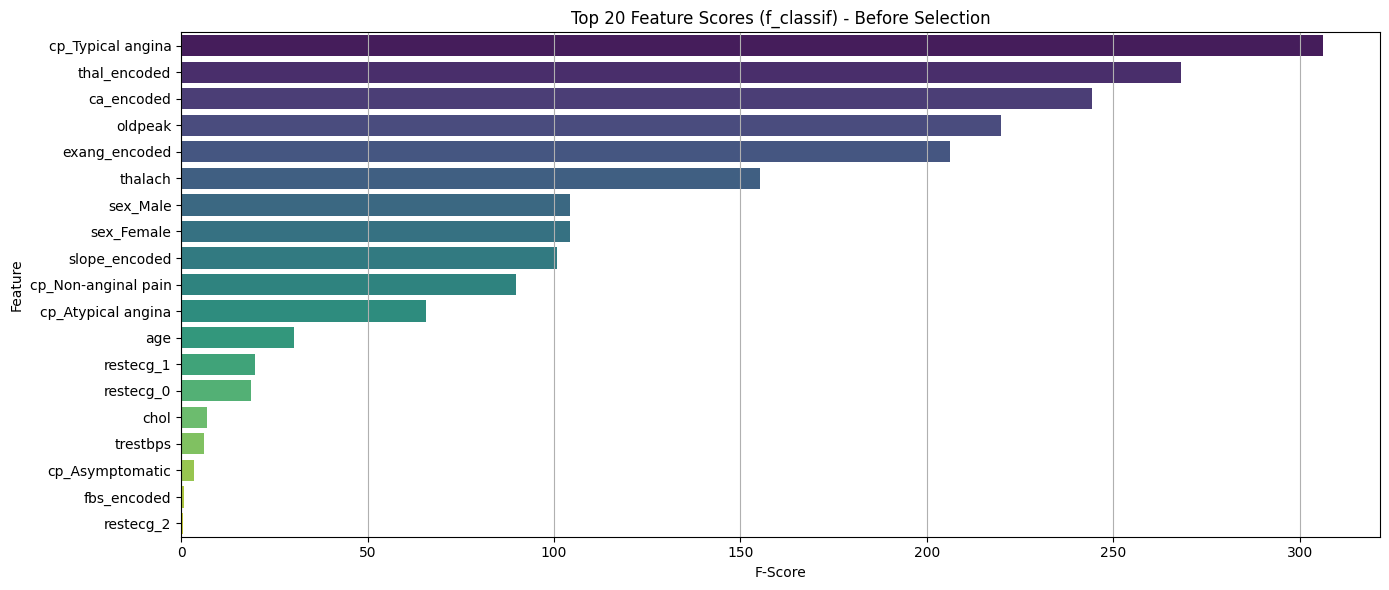

In [17]:
# 4. EDA Visualization - Feature Scores and Selected Features
# --- Plot 1: Feature Scores (All Features) ---
plt.figure(figsize=(14, 6))

# Create a DataFrame for plotting all feature scores
all_scores_df = pd.DataFrame({
    'Feature': X_OutlierD.columns,
    'Score': feature_scores
})
all_scores_df = all_scores_df.sort_values(by='Score', ascending=False)

# Plot top 20 feature scores for clarity
top_20_scores = all_scores_df.head(20)
sns.barplot(data=top_20_scores, x='Score', y='Feature', palette='viridis')
plt.title(f'Top 20 Feature Scores (f_classif) - Before Selection')
plt.xlabel('F-Score')
plt.ylabel('Feature')
plt.grid(axis='x')
plt.tight_layout()
plt.show()



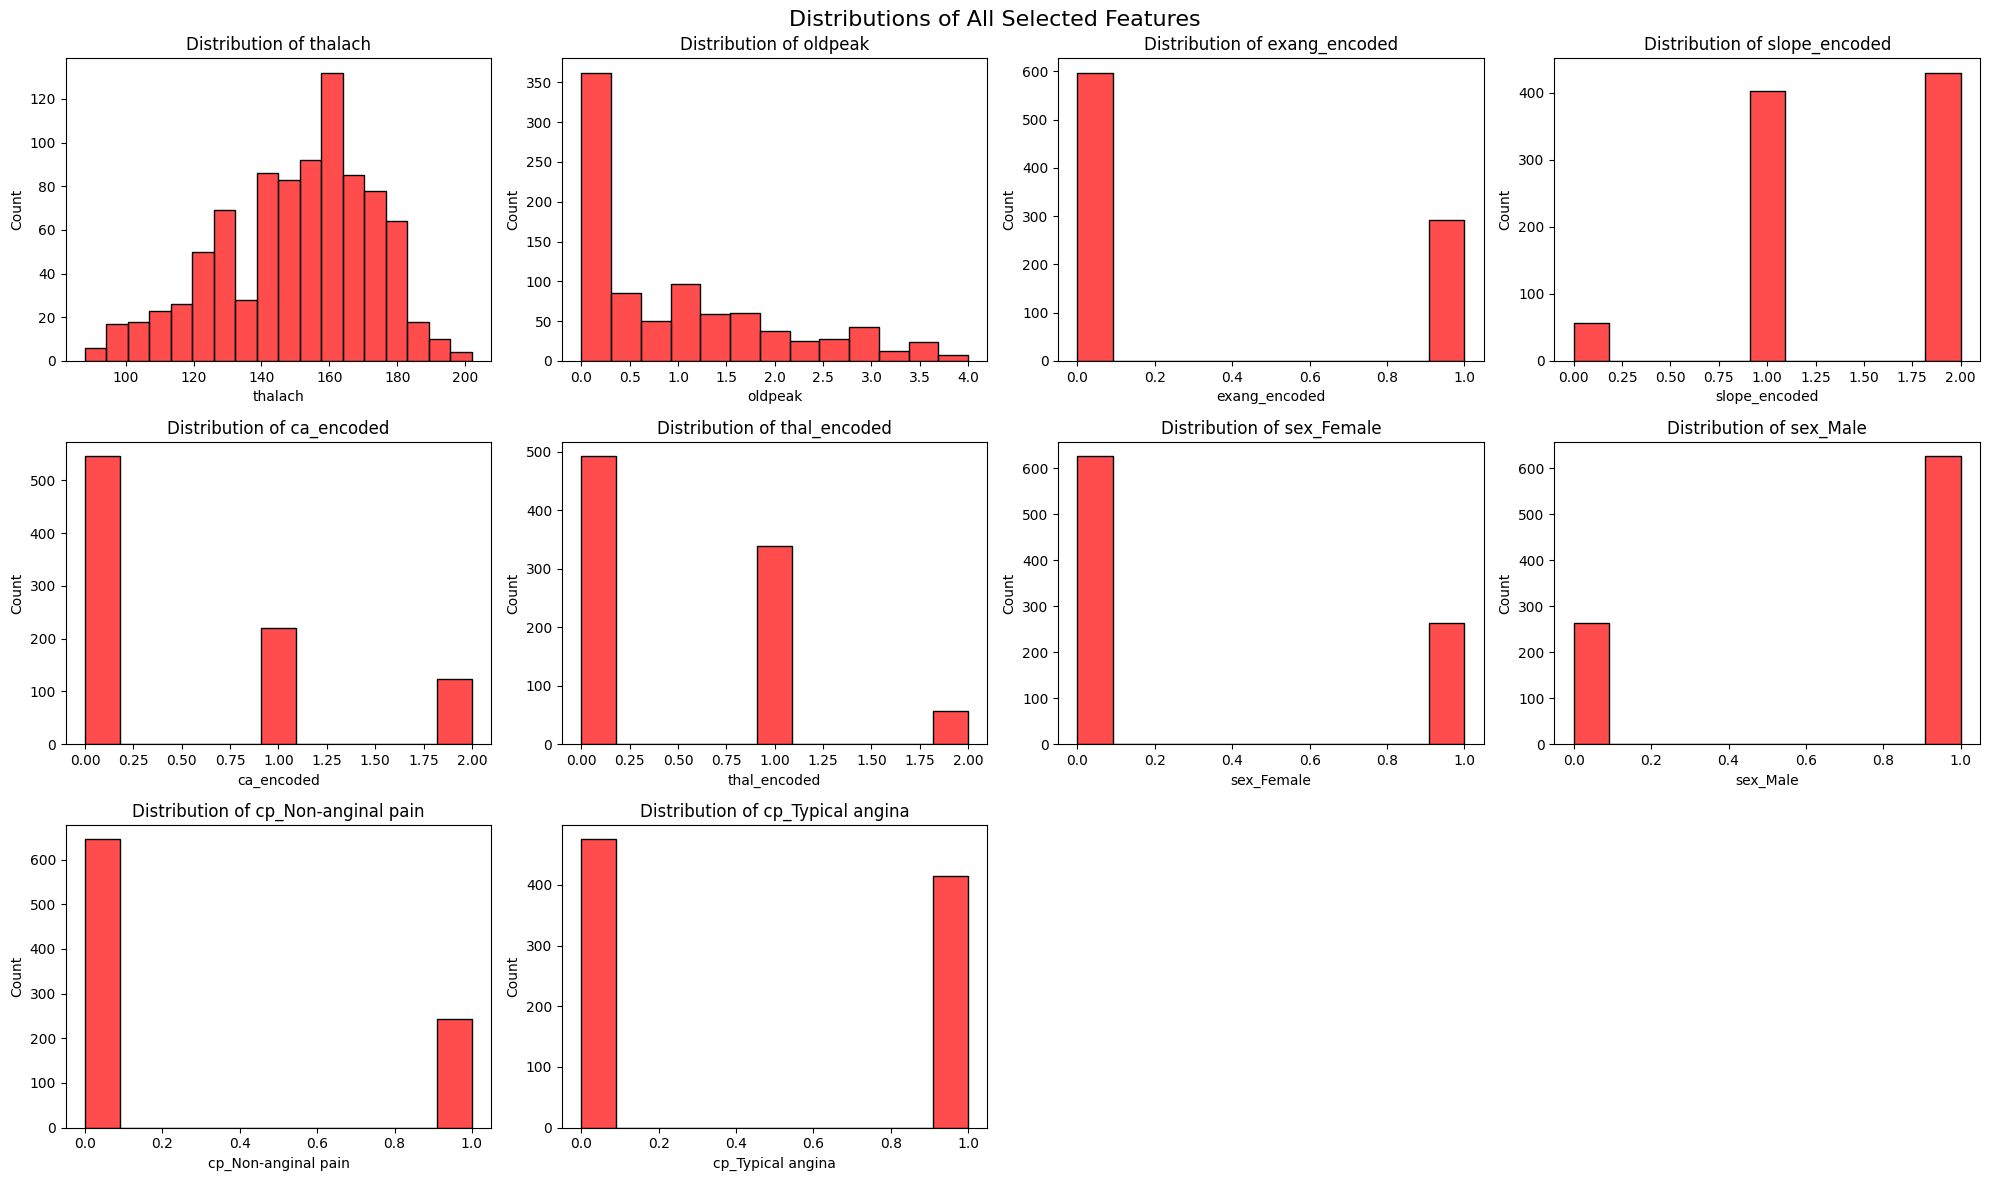

In [18]:
# 4. EDA Visualization - Distribution of ALL Selected Features
# --- Plot 2: Distribution of ALL Selected Features ---
num_selected = len(selected_feature_names)

if num_selected > 0:
    # Determine layout for subplots (e.g., 2 rows, adjust columns based on number of features)
    cols = min(4, num_selected) # Up to 4 columns per row
    rows = (num_selected + cols - 1) // cols # Calculate number of rows needed

    fig, axes = plt.subplots(rows, cols, figsize=(5*cols, 4*rows))

    # If there's only one subplot, make axes iterable
    if num_selected == 1:
        axes = [axes]
    elif rows == 1:
        axes = [axes] if cols == 1 else axes
    else:
        axes = axes.flatten() # Flatten the array for easy iteration

    # Plot histogram for each selected feature
    for i in range(num_selected):
        sns.histplot(data=X_selected_df, x=selected_feature_names[i], ax=axes[i], color='red', alpha=0.7) # Using red color as in your screenshot
        axes[i].set_title(f'Distribution of {selected_feature_names[i]}')
        axes[i].set_xlabel(selected_feature_names[i])
        axes[i].set_ylabel('Count')

    # Hide any unused subplots
    for j in range(num_selected, len(axes)):
        axes[j].set_visible(False)

    plt.suptitle('Distributions of All Selected Features', fontsize=16)
    plt.tight_layout()
    plt.show()
else:
    print("\n--- No features selected (k might be 0). ---")



In [19]:
# Save the dataset after feature selection to a CSV file
df_selected_final.to_csv('/content/heart_cleaned_no_outliers_encoded_features.csv', index=False)